# KeyLeak: Acoustic Side-Channel Attack on a Laptop Keyboard, and Defences Against It

**Question:** can a microphone tell which key was pressed from the sound alone, and can cheap defences stop it?

This notebook is the complete story of the project in one place: the data I collected, how I checked and cleaned it, how the features were built, which models I used and why, how I evaluated them, and every result, including the ones that are not flattering.

**Contents**
1. Idea and threat model
2. Data collection
3. Data audit and cleaning
4. Features
5. Models and why I chose them
6. Evaluation design
7. Experiment 1: how well does the attack work?
8. Experiment 2: do the defences work?
9. Experiment 3: the adaptive attacker
10. Experiment 4: ablations (clip window, high-pass filter)
11. Real-time style test (replay of the live demo)
12. Limitations and honest conclusions
13. How to re-run with more sessions


## 1. Idea and threat model

Each key on a keyboard produces a slightly different click, because of where the key sits on the plate, how the case resonates and which finger presses it. A microphone in the same room (for example the laptop's own microphone during a call) can record those clicks. An **attacker** who has audio of the target's typing, plus some labelled examples of that keyboard, trains a classifier that maps a click to a letter.

**Scope of this study**
- 26 classes (the keys A to Z), one laptop (its built-in keyboard and built-in microphone), one typist.
- **Attack:** MFCC features with an SVM and a Random Forest.
- **Defence:** two cheap, physical ones: dampening (cloth) and controlled background noise.
- **Adaptive attacker:** an attacker who knows about the defence and retrains on defended recordings.

**Ethics.** All audio is my own typing on my own keyboard. No passwords, no other people's typing and no private data were recorded.

In [1]:
import os, sys, re, time, warnings, importlib.util
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import librosa
from scipy.signal import butter, sosfiltfilt
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", message="The number of unique classes")

# ---- locate the project (works from the project root or from final_notebook/)
cwd = Path.cwd()
ROOT = Path(os.environ.get("KEYLEAK_ROOT") or (cwd.parent if cwd.name == "final_notebook" else cwd))
OUT = Path(os.environ.get("KEYLEAK_OUT") or (ROOT / "final_notebook"))
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
RAW = ROOT / "dataset" / "raw"
sys.path.insert(0, str(ROOT / "src"))
import extract_features as ef          # the same feature code used by the command-line scripts

# ---- experiment configuration (edit this cell when you add sessions)
CLEAN = ["session_06", "session_07", "session_11"]           # clean sessions with a key log
DEFENDED = {                                                   # session -> (condition, setup)
    "session_08": ("dampened", "cloth under the stand"),
    "session_09": ("dampened", "cloth over the keys"),
    "session_13": ("dampened", "cloth over the keys"),
    "session_10": ("noisy", "white noise (phone)"),
    "session_12": ("noisy", "white noise (phone)"),
}
DEFENCES = {"White noise": ["session_10", "session_12"],
            "Cloth over the keys": ["session_09", "session_13"]}
TRAIN_BASE = ["session_06", "session_07"]                     # clean training sessions for the defence tests
BASELINE_TEST = "session_11"                                   # clean session the attacker has never heard
PRE, POST, HP = 0.02, 0.08, 0.0                                # clip: 20 ms before to 80 ms after key-down; no high-pass
SEED = 42
FEAT = ([f"mfcc{i}_mean" for i in range(1, ef.N_MFCC)] + [f"mfcc{i}_std" for i in range(1, ef.N_MFCC)])

# ---- plot style: thin marks, quiet grid, colour-blind-safe palette (Okabe-Ito)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10})
C_CLEAN, C_UNDER, C_OVER, C_NOISE, C_GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#767676"

meta = pd.read_csv(ROOT / "dataset" / "metadata_master.csv")
print("project root :", ROOT)
print("metadata rows:", len(meta), "| sessions:", meta.session.nunique())

project root : /sessions/rcw-01to2qvxwerckt8j3rjg3dak/mnt/AcousticKeyword
metadata rows: 368 | sessions: 13


## 2. Data collection

**Recording protocol** (the same for every session that is used in the experiments)
- Built-in laptop microphone, 44.1 kHz mono, laptop on a stand on a wooden table, lid at about 110 degrees, normal typing posture.
- Windows microphone "enhancements" (noise suppression) switched **off** and input volume 100 (see the cleaning section for why).
- **Burst recordings:** for each letter a 5 second recording in which I press that one key five times, about one second apart. The 26 letters are visited in a freshly randomised order every session (the random seed is saved).
- **Key logger:** while recording, a small logger stores the exact time of every press and release of the target key (relative to the first audio sample). Other keys are only counted, never stored. This gives each click a trustworthy label and time.
- A 3 second room-noise recording is saved at the start of every session.
- A take can be redone. Rejected takes are **kept** in a `rejected/` folder and logged in the metadata, never deleted.

**Conditions**
- `clean`: no defence, quiet room.
- `dampened`: cloth under the laptop stand, or a thin cloth laid over the keys.
- `noisy`: steady white noise played from a phone about 50 cm from the laptop.

Sessions 01 to 05 are earlier pilot recordings made before the key logger existed; they are kept as raw data but are not used in the experiments (explained below).

In [2]:
rows = []
used = set(CLEAN) | set(DEFENDED)
for s in sorted(meta.session.unique()):
    m = meta[meta.session == s]
    acc = m[m.quality_flag != "REJECTED"]
    rows.append(dict(session=s, condition=m.condition.iloc[0],
                     recording=", ".join(sorted(m.recording_type.dropna().astype(str).unique())),
                     accepted=len(acc), rejected=int((m.quality_flag == "REJECTED").sum()),
                     clipped=int((acc.quality_flag == "POSSIBLE_CLIPPING").sum()),
                     near_silent=int((acc.quality_flag == "LOW_PEAK").sum()),
                     key_log=(RAW / s / "events").is_dir(),
                     used_in_experiments=s in used))
sessions_table = pd.DataFrame(rows)
display(sessions_table)
n_used = sessions_table[sessions_table.used_in_experiments].accepted.sum()
print(f"\nRecordings used in the experiments: {int(n_used)} burst files = about {int(n_used) * 5} labelled key presses")

,session,condition,recording,accepted,rejected,clipped,near_silent,key_log,used_in_experiments
0,session_01,noisy_pilot,single,78,0,0,36,False,False
1,session_02,noisy_pilot,burst,1,0,0,0,False,False
2,session_03,noisy_pilot,burst,26,0,0,0,False,False
3,session_04,noisy_pilot,burst,1,0,0,0,False,False
4,session_05,clean,burst,26,3,0,0,False,False
5,session_06,clean,burst,26,1,1,0,True,True
6,session_07,clean,burst,26,6,1,0,True,True
7,session_08,dampened,burst,26,3,1,0,True,True
8,session_09,dampened,burst,26,9,0,0,True,True
9,session_10,noisy,burst,26,1,0,0,True,True



Recordings used in the experiments: 208 burst files = about 1040 labelled key presses


## 3. Data audit and cleaning

Before any model was trained I audited the data. Problems found, and what I did about each, in the order they were found:

| Problem found | Evidence | What I did |
|---|---|---|
| **Near-silent clips** in the first pilot session (36 of 78 single-press clips) | peak amplitude below 0.01 | kept as raw data, labelled `noisy_pilot`, **excluded** from the experiments |
| **Inconsistent metadata:** old 7-column file, plus a stale duplicate row for one recording | audit scripts | built a new 14-column `metadata_master.csv`; the original file was left untouched |
| **Windows noise suppression** was silently removing the background and distorting the sound | room noise RMS about 0.0007 with enhancements on versus about 0.01 with them off | enhancements **off**, input volume 100, 48 kHz Windows format, identical for all sessions |
| **Typed letters leaking** into the terminal prompt during a take | stray characters in the prompts | the script now flushes the keyboard buffer after each take |
| **Press counts typed by hand** disagreed with a detector on 9 of 26 files in the first clean session | manual check | replaced hand counts with a **key logger**; that older session has no key log, so it is **not used** in the experiments |
| **Audio and key log misaligned** by about 0.6 s | test run: click minus key-down about -586 ms | rewrote the recorder (microphone stream opened first, key times measured from the first audio sample); see the evidence below |
| **Clipping and wrong press counts** during real sessions | peak near 1.0, logger counts of 4 or 6 | clipped takes flagged (not removed); takes with the wrong count were redone and the rejected take kept |

The next cells show the evidence for the three problems that can be checked from the saved data: alignment, room noise and press counts.

,session,condition,presses,median_ms,p5_ms,p95_ms,reliable_check
0,session_06,clean,130,21.3,19.7,24.0,yes
1,session_07,clean,130,20.7,18.5,25.8,yes
2,session_11,clean,130,18.5,-6.1,21.1,yes
3,session_08,dampened,130,18.1,-4.4,21.3,no: faint clicks
4,session_09,dampened,130,12.4,-37.4,26.0,no: faint clicks
5,session_13,dampened,130,-0.4,-19.2,24.9,no: faint clicks
6,session_10,noisy,130,19.8,16.5,22.5,no: faint clicks
7,session_12,noisy,131,1.8,-35.1,20.1,no: faint clicks


The check finds the loudest point near each logged key-down. On the clean sessions the click is the loudest thing,
so the result is trustworthy. On the cloth and white-noise sessions the click is faint or masked, so the loudest
point is sometimes something else and the spread (p5) gets wide. The recorder code is identical for all sessions,
but alignment on the defended sessions is therefore NOT independently verified by this method.


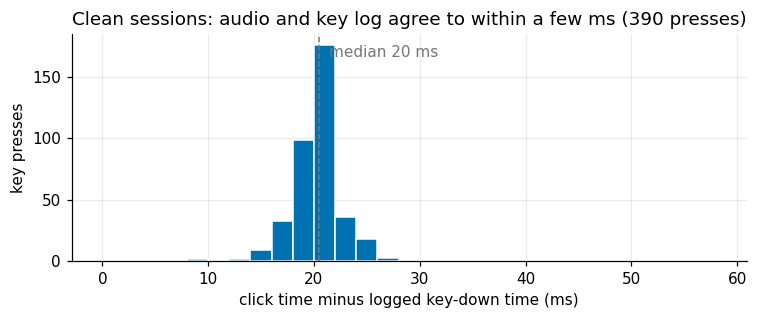

In [3]:
def click_offsets(session):
    # click time (loudest point of the 300 Hz high-passed envelope) minus the logged key-down time, in ms
    offs = []
    for key in ef.KEYS:
        wav = RAW / session / f"{key}_burst.wav"
        if not wav.exists():
            continue
        a, sr = sf.read(wav, dtype="float32")
        a = a[:, 0] if a.ndim == 2 else a
        y = ef.highpass(a, sr, 300)
        h = 44
        n = len(y) // h * h
        env = np.sqrt((y[:n].reshape(-1, h) ** 2).mean(axis=1))
        t = np.arange(len(env)) * h / sr
        for d in ef.read_down_times(RAW / session / "events" / f"{key}_events.csv", key):
            i = np.where((t >= d - 0.1) & (t <= d + 0.15))[0]
            if len(i):
                offs.append((t[i[np.argmax(env[i])]] - d) * 1000)
    return np.array(offs)

all_sessions = CLEAN + list(DEFENDED)
off = {s: click_offsets(s) for s in all_sessions}
rows = [dict(session=s, condition=meta.loc[meta.session == s, "condition"].iloc[0], presses=len(o),
             median_ms=round(float(np.median(o)), 1), p5_ms=round(float(np.percentile(o, 5)), 1),
             p95_ms=round(float(np.percentile(o, 95)), 1),
             reliable_check="yes" if s in CLEAN else "no: faint clicks")
        for s, o in off.items()]
display(pd.DataFrame(rows))
print("The check finds the loudest point near each logged key-down. On the clean sessions the click is the loudest thing,")
print("so the result is trustworthy. On the cloth and white-noise sessions the click is faint or masked, so the loudest")
print("point is sometimes something else and the spread (p5) gets wide. The recorder code is identical for all sessions,")
print("but alignment on the defended sessions is therefore NOT independently verified by this method.")

fig, ax = plt.subplots(figsize=(7, 3))
allo = np.concatenate([off[s] for s in CLEAN])
ax.hist(allo, bins=np.arange(0, 60, 2), color=C_CLEAN, edgecolor="white")
ax.axvline(np.median(allo), color=C_GREY, ls="--", lw=1)
ax.text(np.median(allo) + 1, ax.get_ylim()[1] * 0.9, f"median {np.median(allo):.0f} ms", color=C_GREY)
ax.set_xlabel("click time minus logged key-down time (ms)")
ax.set_ylabel("key presses")
ax.set_title(f"Clean sessions: audio and key log agree to within a few ms ({len(allo)} presses)")
fig.tight_layout(); fig.savefig(FIG / "alignment.png"); plt.show()

In [4]:
# room noise by frequency band: a white-noise session shows up as extra energy between 200 Hz and 8 kHz,
# a low rumble shows up only below 200 Hz
def noise_bands(session):
    p = RAW / session / "ambient" / "noise_floor.wav"
    if not p.exists():
        return None
    x, sr = sf.read(p, dtype="float32")
    x = x[:, 0] if x.ndim == 2 else x
    P = np.abs(np.fft.rfft(x)) ** 2 / len(x) ** 2
    f = np.fft.rfftfreq(len(x), 1 / sr)
    band = lambda lo, hi: float(np.sqrt(2 * P[(f >= lo) & (f < hi)].sum()))
    return dict(session=session, condition=meta.loc[meta.session == session, "condition"].iloc[0],
                total_rms=round(float(np.sqrt((x ** 2).mean())), 5), below_200Hz=round(band(0, 200), 5),
                f200_2k=round(band(200, 2000), 5), f2k_8k=round(band(2000, 8000), 5))

nb = [r for r in (noise_bands(s) for s in all_sessions) if r]
nb_df = pd.DataFrame(nb)
display(nb_df)
print()

# press counts: every accepted take should hold exactly 5 logged presses
acc = meta[(meta.quality_flag != "REJECTED") & (meta.session.isin(all_sessions))]
print("accepted takes in the experiment sessions:", len(acc))
print("logged press counts:", dict(Counter(acc.actual_presses.astype(int))))
print("rejected takes kept in rejected/ folders :", int((meta[meta.session.isin(all_sessions)].quality_flag == "REJECTED").sum()))

,session,condition,total_rms,below_200Hz,f200_2k,f2k_8k
0,session_06,clean,0.01173,0.01166,0.00120,0.00048
1,session_07,clean,0.01192,0.01182,0.00155,0.00052
2,session_11,clean,0.01837,0.01836,0.00171,0.00049
3,session_08,dampened,0.01143,0.01137,0.00162,0.00060
4,session_09,dampened,0.01424,0.01405,0.00234,0.00061
5,session_13,dampened,0.01184,0.01171,0.00187,0.00051
6,session_10,noisy,0.01849,0.01462,0.01090,0.00272
7,session_12,noisy,0.01739,0.01113,0.01178,0.00586



accepted takes in the experiment sessions: 208
logged press counts: {5: 207, 6: 1}
rejected takes kept in rejected/ folders : 25


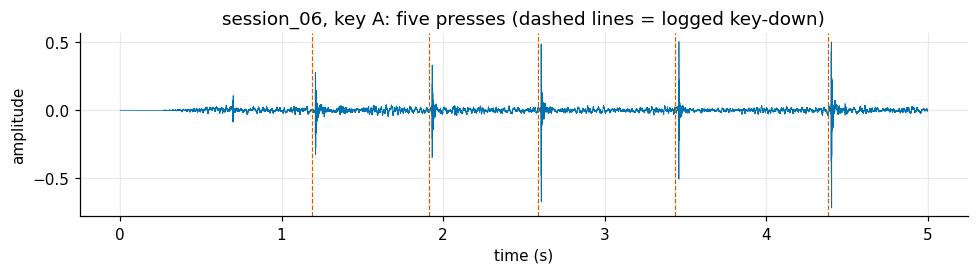

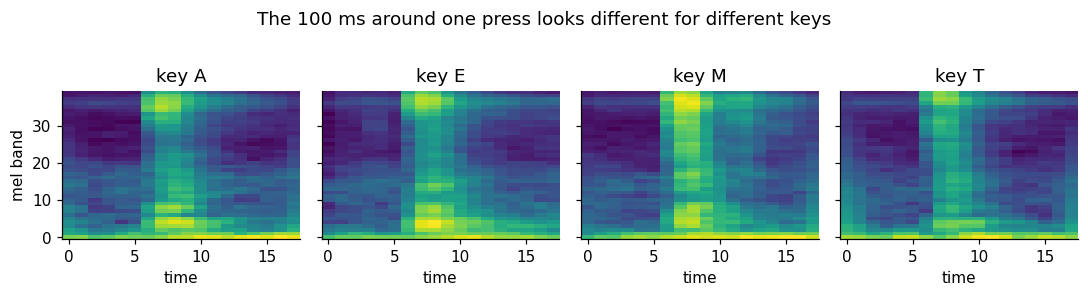

In [5]:
# what the raw signal looks like: one 5 s burst with the logged key-downs, and a mel spectrogram of four different keys
s0 = CLEAN[0]
a, sr = sf.read(RAW / s0 / "A_burst.wav", dtype="float32")
a = a[:, 0] if a.ndim == 2 else a
downs = ef.read_down_times(RAW / s0 / "events" / "A_events.csv", "A")

fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(np.arange(len(a)) / sr, a, color=C_CLEAN, lw=0.5)
for d in downs:
    ax.axvline(d, color=C_NOISE, lw=0.8, ls="--")
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude")
ax.set_title(f"{s0}, key A: five presses (dashed lines = logged key-down)")
fig.tight_layout(); fig.savefig(FIG / "waveform.png"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6), sharey=True)
for ax, key in zip(axes, ["A", "E", "M", "T"]):
    aa, sr = sf.read(RAW / s0 / f"{key}_burst.wav", dtype="float32")
    aa = aa[:, 0] if aa.ndim == 2 else aa
    d = ef.read_down_times(RAW / s0 / "events" / f"{key}_events.csv", key)[0]
    clip = aa[int(round((d - PRE) * sr)):int(round((d + POST) * sr))]
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=clip, sr=sr, n_fft=ef.N_FFT, hop_length=ef.HOP, n_mels=ef.N_MELS))
    ax.imshow(S, origin="lower", aspect="auto", cmap="viridis")
    ax.set_title(f"key {key}"); ax.set_xlabel("time"); ax.grid(False)
axes[0].set_ylabel("mel band")
fig.suptitle("The 100 ms around one press looks different for different keys", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "spectrograms.png", bbox_inches="tight"); plt.show()

## 4. Features

For every logged key-down, one clip is cut from 20 ms before to 80 ms after the key-down (100 ms in total). That window holds the press click, where the key bottoms out. Using the logged time means the labels are exact.

Each clip is then turned into a small fixed-length description:
1. Scale the clip so its loudest sample is 1, so that how hard I pressed does not leak in as a clue.
2. Compute **MFCCs** (Mel-frequency cepstral coefficients): a compact summary of the spectrum on a perceptual (mel) frequency scale. 20 coefficients per short frame, using a 1024-sample FFT and a hop of 256, with 40 mel bands.
3. Drop coefficient 0, which only measures loudness.
4. For each of the remaining 19 coefficients keep the **mean and the standard deviation over time**.

That gives **38 numbers per key press**.

A note on honesty: because I cut clips with the *logged* press times, segmentation is not part of what is being tested. A real attacker would not have a key log. The live demo (section 11) therefore also tests a version where the clicks are found from the audio alone.

In [6]:
def build(sessions, pre=PRE, post=POST, hp=HP):
    # one row per logged key press: session, condition, key, press_index and the 38 features
    out = []
    for s in sessions:
        cond = meta.loc[meta.session == s, "condition"].iloc[0]
        for key in ef.KEYS:
            wav = RAW / s / f"{key}_burst.wav"
            evf = RAW / s / "events" / f"{key}_events.csv"
            audio, sr = sf.read(wav, dtype="float32")
            audio = audio[:, 0] if audio.ndim == 2 else audio
            if hp > 0:
                audio = ef.highpass(audio, sr, hp)
            for idx, t in enumerate(ef.read_down_times(evf, key), start=1):
                a0, a1 = int(round((t - pre) * sr)), int(round((t + post) * sr))
                if a0 < 0 or a1 > len(audio):
                    continue            # a press too close to the end of the recording (rare, counted below)
                feats, _, _ = ef.clip_features(audio[a0:a1], sr)
                out.append(dict(session=s, condition=cond, key=key, press_index=idx,
                                **{n: float(v) for n, v in zip(FEAT, feats)}))
    return pd.DataFrame(out)

t0 = time.time()
ALL = build(all_sessions)
print(f"{len(ALL)} key presses x {len(FEAT)} features   ({time.time() - t0:.0f} s)")
display(ALL.groupby(["session", "condition"]).size().rename("presses").to_frame().T)

# consistency check against the features file made by the command-line script (if it exists)
csvs = sorted((ROOT / "results").glob("features_*.csv"), key=lambda p: p.stat().st_mtime)
for p in reversed(csvs):
    ref = pd.read_csv(p)
    if set(all_sessions) <= set(ref.session):
        ref = ref[ref.session.isin(all_sessions)].set_index(["session", "key", "press_index"])
        mine = ALL.set_index(["session", "key", "press_index"])
        common = mine.index.intersection(ref.index)
        diff = float(np.abs(mine.loc[common, FEAT].values - ref.loc[common, FEAT].values).max())
        print(f"matches {p.name}: {len(common)} presses compared, largest difference {diff:.2e}")
        break

1040 key presses x 38 features   (13 s)


session,session_06,session_07,session_08,session_09,session_10,session_11,session_12,session_13
condition,clean,clean,dampened,dampened,noisy,clean,noisy,dampened
presses,130,130,129,130,130,130,131,130


matches features_s06_s07_s08_s09_s10_s11_s12_s13_pre20_post80.csv: 1040 presses compared, largest difference 7.63e-06


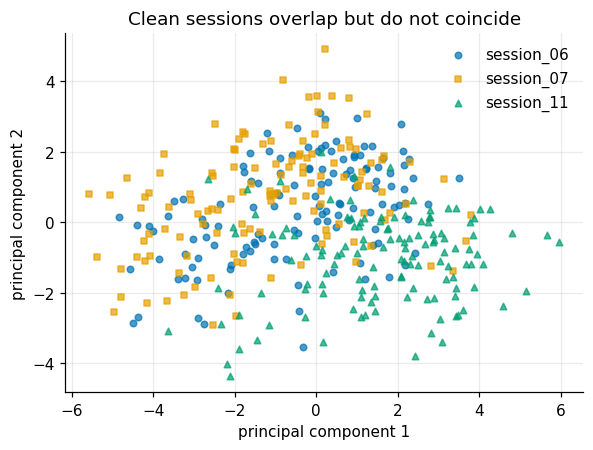

In [7]:
# do the sessions differ from each other? PCA of the 38 features of the clean sessions
pool = ALL[ALL.session.isin(CLEAN)]
Z = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(pool[FEAT].values))
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for s, mk, col in zip(CLEAN, ["o", "s", "^"], [C_CLEAN, C_UNDER, C_OVER]):
    m = (pool.session == s).values
    ax.scatter(Z[m, 0], Z[m, 1], marker=mk, s=18, alpha=0.7, color=col, label=s)
ax.set_xlabel("principal component 1"); ax.set_ylabel("principal component 2")
ax.set_title("Clean sessions overlap but do not coincide")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "pca_sessions.png"); plt.show()

## 5. Models and why I chose them

I used two classical models, deliberately simple, because the dataset is small (a few hundred labelled clicks per session).

- **Support Vector Machine with an RBF kernel (SVM).** Works well on small datasets with a modest number of features, finds non-linear boundaries between classes, and is a standard choice for MFCC-style audio features. The regularisation strength `C` is chosen by cross-validation on the training data only. Its `decision_function` gives a score per key, which I use to rank guesses (top-3 and top-5).
- **Random Forest (300 trees).** A completely different model family (many decision trees voting). It needs little tuning, copes with unscaled and noisy features, and gives class probabilities. If both models behave similarly, the result is less likely to be an accident of one algorithm.

I did **not** use deep learning: with 5 presses per key per session there is not enough data, and the goal is to measure the effect of the defences, not to win an accuracy contest. Features are standardised (zero mean, unit variance) using **training data only**.

## 6. Evaluation design

The most important design decision in the project:

> **The attacker is always tested on a recording session it has never heard.**

If clips from the same recording end up on both sides of a train/test split, the model can recognise the *session* (the room, the way I typed that day) instead of the *key*, and the accuracy looks far better than it really is. Experiment 1 shows how large that effect is.

Rules I followed:
- Train and test sessions are always different sessions.
- Standardisation and the SVM `C` value are fitted on training data only. Test sessions are never used for any choice.
- Metrics are **top-1** (is the first guess right?), **top-3** and **top-5** accuracy. Guessing at random gives 3.8%, 11.5% and 19.2%.
- Each test session has about 130 presses, so a top-1 accuracy has about **±7 points** of statistical uncertainty (95% interval, shown as error bars). Differences smaller than that should not be trusted.
- Conditions are labelled honestly (`clean`, `dampened`, `noisy`) and every defended session is only compared with clean sessions recorded with the same setup otherwise.

In [8]:
CHANCE1, CHANCE3, CHANCE5 = 100 / 26, 300 / 26, 500 / 26

def topk(scores, classes, y, k):
    order = np.argsort(-scores, axis=1)[:, :k]
    return float(np.mean([yy in classes[r] for yy, r in zip(y, order)])) * 100

def ci95(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n) * 100

def fit(train):
    sc = StandardScaler().fit(train[FEAT].values)
    X, y = sc.transform(train[FEAT].values), train.key.values
    cv = StratifiedKFold(int(min(5, Counter(y).most_common()[-1][1])), shuffle=True, random_state=SEED)
    svm = GridSearchCV(SVC(kernel="rbf", gamma="scale", decision_function_shape="ovr"),
                       {"C": [1, 10, 100]}, cv=cv).fit(X, y).best_estimator_
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X, y)
    return sc, svm, rf

def evaluate(models, test):
    sc, svm, rf = models
    X, y = sc.transform(test[FEAT].values), test.key.values
    out = {"n": len(y), "y": y}
    for name, m, scores in (("SVM", svm, svm.decision_function(X)), ("RF", rf, rf.predict_proba(X))):
        pred = m.predict(X)
        acc = float(np.mean(pred == y))
        out[name] = dict(top1=acc * 100, ci=ci95(acc, len(y)), top3=topk(scores, m.classes_, y, 3),
                         top5=topk(scores, m.classes_, y, 5), pred=pred)
    return out

def run(train_sessions, test_session, df=None):
    df = ALL if df is None else df
    assert test_session not in train_sessions, "test session must differ from the training sessions"
    return evaluate(fit(df[df.session.isin(train_sessions)]), df[df.session == test_session])

def short(ss):
    return "+".join(s.replace("session_", "") for s in ss)

print("helpers ready")

helpers ready


## 7. Experiment 1: how well does the attack work?

Three clean sessions (06, 07, 11) let me test the attacker on a session it has not heard in every possible way:
- **2 training sessions, 1 test session** (leave one session out): 3 combinations.
- **1 training session, 1 test session**: 6 combinations. Comparing 1 versus 2 training sessions shows how much more data helps.

2 training sessions -> 1 unseen session (leave one session out)


,train,test,n_train,SVM_top1,SVM_top3,SVM_top5,RF_top1,RF_top3,RF_top5
0,07+11,06,260,34.6,65.4,72.3,33.8,60.0,74.6
1,06+11,07,260,27.7,58.5,71.5,39.2,64.6,74.6
2,06+07,11,260,21.5,44.6,57.7,23.8,45.4,63.8


1 training session -> 1 unseen session


,train,test,n_train,SVM_top1,SVM_top5,RF_top1,RF_top5
0,06,07,130,28.5,68.5,30.0,62.3
1,06,11,130,17.7,50.8,23.1,60.8
2,07,06,130,30.8,64.6,30.0,63.8
3,07,11,130,13.8,50.0,17.7,46.9
4,11,06,130,20.8,53.8,20.0,57.7
5,11,07,130,16.2,45.4,14.6,52.3


chance: top-1 3.8%   top-3 11.5%   top-5 19.2%


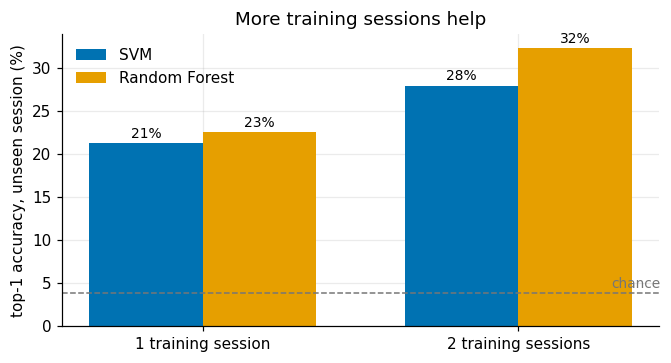

In [9]:
loso_rows, y_all, p_all = [], [], []
for held in CLEAN:
    tr = [s for s in CLEAN if s != held]
    r = run(tr, held)
    loso_rows.append(dict(train=short(tr), test=short([held]), n_train=int(ALL.session.isin(tr).sum()),
                          SVM_top1=r["SVM"]["top1"], SVM_top3=r["SVM"]["top3"], SVM_top5=r["SVM"]["top5"],
                          RF_top1=r["RF"]["top1"], RF_top3=r["RF"]["top3"], RF_top5=r["RF"]["top5"]))
    y_all += list(r["y"]); p_all += list(r["SVM"]["pred"])
loso = pd.DataFrame(loso_rows)

pair_rows = []
for a in CLEAN:
    for b in CLEAN:
        if a != b:
            r = run([a], b)
            pair_rows.append(dict(train=short([a]), test=short([b]), n_train=int((ALL.session == a).sum()),
                                  SVM_top1=r["SVM"]["top1"], SVM_top5=r["SVM"]["top5"],
                                  RF_top1=r["RF"]["top1"], RF_top5=r["RF"]["top5"]))
pairs = pd.DataFrame(pair_rows)

print("2 training sessions -> 1 unseen session (leave one session out)")
display(loso.round(1))
print("1 training session -> 1 unseen session")
display(pairs.round(1))
print(f"chance: top-1 {CHANCE1:.1f}%   top-3 {CHANCE3:.1f}%   top-5 {CHANCE5:.1f}%")

fig, ax = plt.subplots(figsize=(6.2, 3.4))
vals = {"1 training session": (pairs.SVM_top1.mean(), pairs.RF_top1.mean()),
        "2 training sessions": (loso.SVM_top1.mean(), loso.RF_top1.mean())}
x = np.arange(2); w = 0.36
for j, (name, col) in enumerate((("SVM", C_CLEAN), ("Random Forest", C_UNDER))):
    b = ax.bar(x + (j - 0.5) * w, [v[j] for v in vals.values()], w, color=col, label=name)
    for rect in b:
        ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.6, f"{rect.get_height():.0f}%", ha="center", fontsize=9)
ax.axhline(CHANCE1, color=C_GREY, ls="--", lw=1); ax.text(1.45, CHANCE1 + 0.6, "chance", color=C_GREY, ha="right", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(vals.keys()); ax.set_ylabel("top-1 accuracy, unseen session (%)")
ax.set_title("More training sessions help"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "more_data.png"); plt.show()

**Reading the result.** Trained on two sessions, the attacker gets between 21% and 35% top-1 (SVM, mean 28%) and 58% to 72% top-5 on a session it has never heard. Trained on one session the average is 21% (SVM). Chance is 3.8% top-1 and 19% top-5, so the attack clearly works, and it clearly improves with more training sessions. The sessions are not equally easy: session 11 is the hardest to predict in every combination (13% to 24% top-1). It was recorded days after the others and has a louder low-frequency room rumble, which may be part of the reason, but I have not proven that. This matters later: the clean baseline used in the defence comparison is session 11, so it is on the pessimistic side. The average over the three held-out clean sessions is 28%.

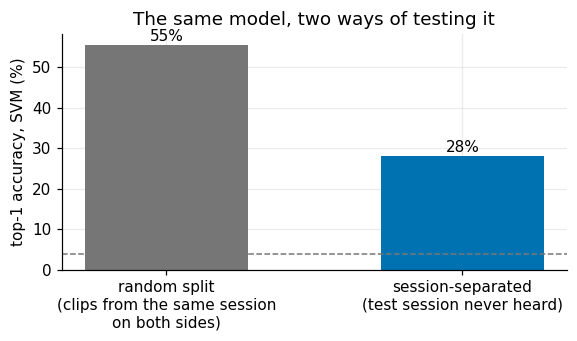

random split: 55.4%   session-separated: 27.9%


In [10]:
# Why session-separated testing matters: the same model, tested the easy way and the honest way
pool = ALL[ALL.session.isin(CLEAN)]
leaky = cross_val_score(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")),
                        pool[FEAT].values, pool.key.values,
                        cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).mean() * 100
honest = loso.SVM_top1.mean()

fig, ax = plt.subplots(figsize=(5.4, 3.2))
b = ax.bar(["random split\n(clips from the same session\non both sides)", "session-separated\n(test session never heard)"],
           [leaky, honest], color=[C_GREY, C_CLEAN], width=0.55)
for rect in b:
    ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 1, f"{rect.get_height():.0f}%", ha="center")
ax.axhline(CHANCE1, color=C_GREY, ls="--", lw=1)
ax.set_ylabel("top-1 accuracy, SVM (%)"); ax.set_title("The same model, two ways of testing it")
fig.tight_layout(); fig.savefig(FIG / "leaky_vs_honest.png"); plt.show()
print(f"random split: {leaky:.1f}%   session-separated: {honest:.1f}%")

**Reading the result.** The same model scores 55% when clips from the same sessions are on both sides of the split, and 28% when it is tested on a session it has never heard. In the random split the model can partly recognise the session (the room, the day, how I typed) instead of the key. Every other number in this notebook uses the honest, session-separated version.

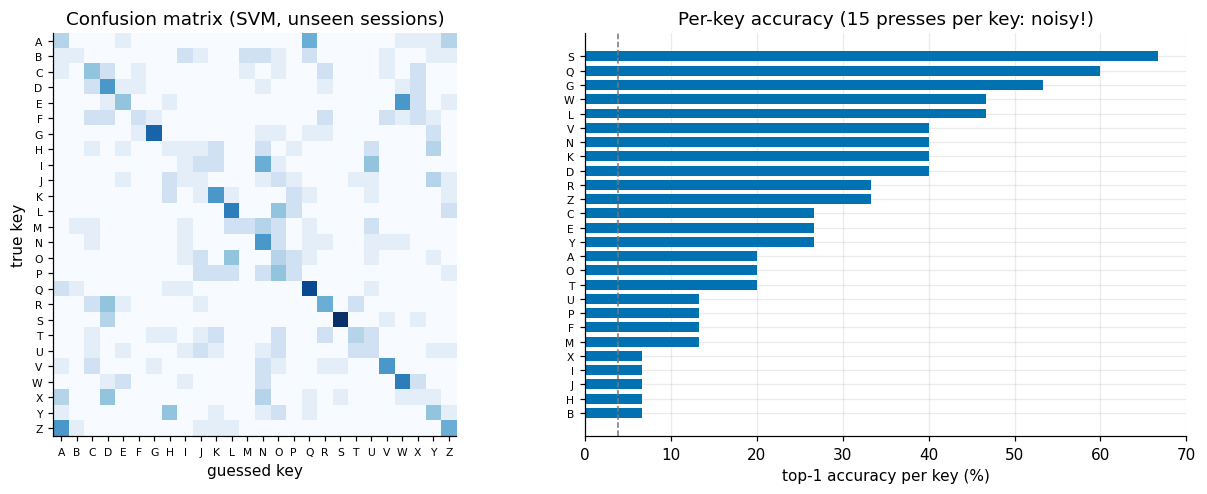

most common mistakes (true -> guessed, count): E->W:6, Z->A:6, A->Q:5, I->N:5, O->L:4, R->D:4, Y->H:4, X->D:4
best keys : S 67%, Q 60%, G 53%, W 47%, L 47%
worst keys: B 7%, H 7%, J 7%, I 7%, X 7%


In [11]:
# which keys are easy or hard? pooled over the three leave-one-session-out runs (15 presses per key)
y_all, p_all = np.array(y_all), np.array(p_all)
keys = ef.KEYS
cm = np.zeros((26, 26), dtype=int)
for t, p in zip(y_all, p_all):
    cm[keys.index(t), keys.index(p)] += 1
per_key = np.diag(cm) / cm.sum(axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(cm, cmap="Blues"); axes[0].grid(False)
axes[0].set_xticks(range(26)); axes[0].set_xticklabels(keys, fontsize=7)
axes[0].set_yticks(range(26)); axes[0].set_yticklabels(keys, fontsize=7)
axes[0].set_xlabel("guessed key"); axes[0].set_ylabel("true key")
axes[0].set_title("Confusion matrix (SVM, unseen sessions)")
order = np.argsort(per_key)
axes[1].barh([keys[i] for i in order], per_key[order], color=C_CLEAN, height=0.7)
axes[1].axvline(CHANCE1, color=C_GREY, ls="--", lw=1)
axes[1].set_xlabel("top-1 accuracy per key (%)"); axes[1].tick_params(axis="y", labelsize=7)
axes[1].set_title("Per-key accuracy (15 presses per key: noisy!)")
fig.tight_layout(); fig.savefig(FIG / "confusion.png"); plt.show()

conf = Counter((t, p) for t, p in zip(y_all, p_all) if t != p)
print("most common mistakes (true -> guessed, count):", ", ".join(f"{t}->{p}:{c}" for (t, p), c in conf.most_common(8)))
print("best keys :", ", ".join(f"{keys[i]} {per_key[i]:.0f}%" for i in order[::-1][:5]))
print("worst keys:", ", ".join(f"{keys[i]} {per_key[i]:.0f}%" for i in order[:5]))

**Reading the result.** Some keys are much easier than others (pooled over the three runs: S 67%, Q 60%, G 53% versus B, H, I, J and X at 7%), but with only 15 presses per key these per-key figures are noisy. Several of the most common mistakes are neighbouring keys (Z and A, A and Q, E and W), which fits the idea that nearby keys sound alike. Others (I as N, R as D) are not neighbours, and the sample is too small to claim a pattern.

## 8. Experiment 2: do the defences work?

The attacker is trained on **clean** typing only (sessions 06 and 07) and tested on sessions it has never heard: a clean one (session 11, the baseline) and each defended one. If a defence works, accuracy falls well below the clean baseline.

,setup,session,n,SVM_top1,SVM_pm,SVM_top3,SVM_top5,RF_top1,RF_top5
0,clean (baseline),11,130,21.5,7.1,44.6,57.7,23.8,63.8
1,cloth under stand,08,129,17.8,6.6,37.2,50.4,17.1,55.0
2,cloth over keys (a),09,130,7.7,4.6,21.5,30.0,7.7,30.8
3,cloth over keys (b),13,130,11.5,5.5,25.4,40.0,11.5,34.6
4,white noise (a),10,130,3.8,3.3,10.8,18.5,9.2,37.7
5,white noise (b),12,131,3.8,3.3,11.5,19.1,6.1,21.4


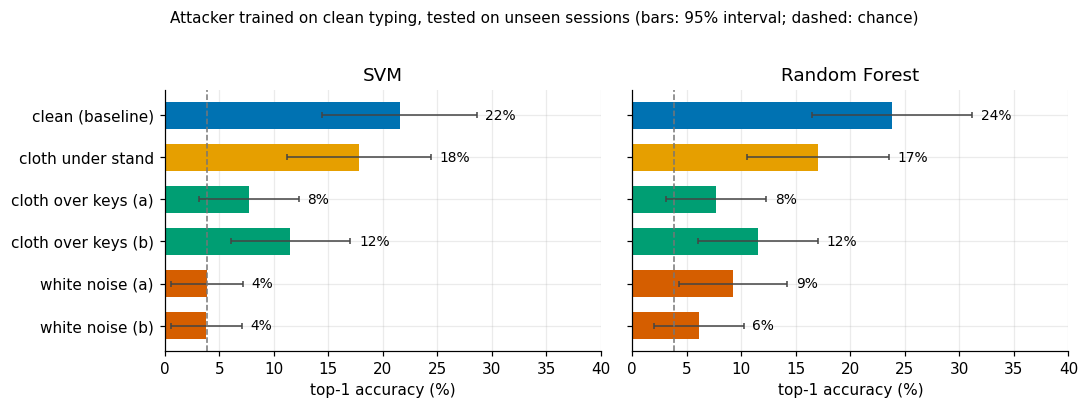

In [12]:
setups = [("clean (baseline)", BASELINE_TEST, C_CLEAN),
          ("cloth under stand", "session_08", C_UNDER),
          ("cloth over keys (a)", "session_09", C_OVER), ("cloth over keys (b)", "session_13", C_OVER),
          ("white noise (a)", "session_10", C_NOISE), ("white noise (b)", "session_12", C_NOISE)]
res2 = {lab: run(TRAIN_BASE, s) for lab, s, _ in setups}

tbl = pd.DataFrame([dict(setup=lab, session=s.replace("session_", ""), n=res2[lab]["n"],
                         SVM_top1=res2[lab]["SVM"]["top1"], SVM_pm=res2[lab]["SVM"]["ci"],
                         SVM_top3=res2[lab]["SVM"]["top3"], SVM_top5=res2[lab]["SVM"]["top5"],
                         RF_top1=res2[lab]["RF"]["top1"], RF_top5=res2[lab]["RF"]["top5"]) for lab, s, _ in setups])
display(tbl.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, model, title in zip(axes, ("SVM", "RF"), ("SVM", "Random Forest")):
    labs = [lab for lab, _, _ in setups][::-1]
    cols = [c for _, _, c in setups][::-1]
    v = [res2[l][model]["top1"] for l in labs]
    e = [res2[l][model]["ci"] for l in labs]
    ax.barh(labs, v, xerr=e, color=cols, height=0.65, error_kw=dict(lw=1, capsize=2, ecolor="#444"))
    for i, val in enumerate(v):
        ax.text(val + e[i] + 0.8, i, f"{val:.0f}%", va="center", fontsize=9)
    ax.axvline(CHANCE1, color=C_GREY, ls="--", lw=1)
    ax.set_xlabel("top-1 accuracy (%)"); ax.set_title(title); ax.set_xlim(0, 40)
fig.suptitle("Attacker trained on clean typing, tested on unseen sessions (bars: 95% interval; dashed: chance)", y=1.02, fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "defences.png", bbox_inches="tight"); plt.show()

**Reading the result.** An attacker trained on clean typing only drops from 21.5% top-1 (clean baseline, session 11) to 18% with the cloth under the stand, which is inside the uncertainty and therefore **no reliable effect**; to 8% and 12% with the cloth over the keys; and to 3.8%, exactly chance, with white noise (SVM; the Random Forest keeps 6% to 9%). Both models give the same ordering: white noise is the strongest, the cloth over the keys is a clear but smaller effect, and the cloth under the stand does nothing measurable. The baseline is the hardest clean session (see Experiment 1), so against a typical clean session the defences may reduce accuracy by more than shown here.

## 9. Experiment 3: the adaptive attacker

A defence that only works against an attacker who does not know about it is weak. Here the attacker **knows the defence** and trains on defended recordings. For each defence I recorded two sessions, so the attacker can train on one and be tested on the other (never the same session).

Three attackers per defence:
1. **Clean-trained** (as before): never saw defended audio.
2. **Adaptive:** trained on *one* defended session, tested on the *other* (both directions).
3. **Adaptive plus clean:** trained on the clean sessions *and* one defended session, tested on the other.

For fairness there is also a **reference**: no defence at all, but only one clean training session (the same amount of training data the adaptive attacker has).

White noise


,attacker,SVM_top1,SVM_pm,SVM_top5,RF_top1,RF_pm,RF_top5
0,"no defence, 1 clean training session (reference)",15.8,4.4,50.4,20.4,4.9,53.8
1,"no defence, 2 clean training sessions (reference)",21.5,7.1,57.7,23.8,7.3,63.8
2,clean-trained attacker,3.8,2.3,18.8,7.7,3.2,29.5
3,adaptive: 1 defended session,5.7,2.8,22.6,6.9,3.1,28.4
4,adaptive + clean sessions,7.3,3.2,29.9,9.6,3.6,33.3


Cloth over the keys


,attacker,SVM_top1,SVM_pm,SVM_top5,RF_top1,RF_pm,RF_top5
0,"no defence, 1 clean training session (reference)",15.8,4.4,50.4,20.4,4.9,53.8
1,"no defence, 2 clean training sessions (reference)",21.5,7.1,57.7,23.8,7.3,63.8
2,clean-trained attacker,9.6,3.6,35.0,9.6,3.6,32.7
3,adaptive: 1 defended session,10.8,3.8,39.6,11.9,3.9,39.6
4,adaptive + clean sessions,14.6,4.3,48.1,17.3,4.6,43.8


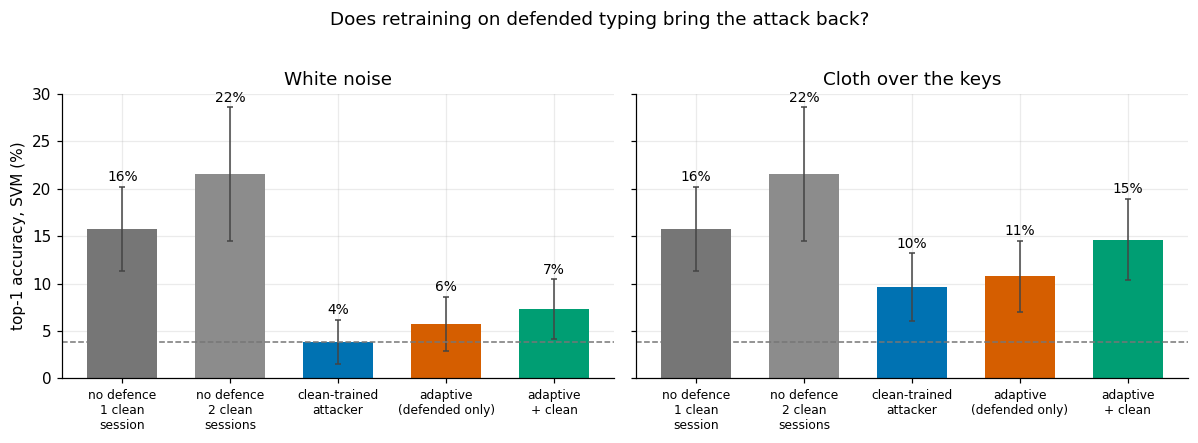

In [13]:
def mean_row(label, runs):
    n = sum(r["n"] for r in runs)
    out = dict(attacker=label)
    for m in ("SVM", "RF"):
        t1 = float(np.average([r[m]["top1"] for r in runs], weights=[r["n"] for r in runs]))
        out[f"{m}_top1"] = t1
        out[f"{m}_pm"] = ci95(t1 / 100, n)
        out[f"{m}_top5"] = float(np.average([r[m]["top5"] for r in runs], weights=[r["n"] for r in runs]))
    return out

ref_runs = [run([a], BASELINE_TEST) for a in TRAIN_BASE]
adaptive_rows = []
for name, (d1, d2) in DEFENCES.items():
    block = [mean_row("no defence, 1 clean training session (reference)", ref_runs),
             mean_row("no defence, 2 clean training sessions (reference)", [run(TRAIN_BASE, BASELINE_TEST)]),
             mean_row("clean-trained attacker", [run(TRAIN_BASE, d1), run(TRAIN_BASE, d2)]),
             mean_row("adaptive: 1 defended session", [run([d1], d2), run([d2], d1)]),
             mean_row("adaptive + clean sessions", [run(TRAIN_BASE + [d1], d2), run(TRAIN_BASE + [d2], d1)])]
    for b in block:
        b["defence"] = name
    adaptive_rows += block
adaptive = pd.DataFrame(adaptive_rows)
for name in DEFENCES:
    print(name)
    display(adaptive[adaptive.defence == name].drop(columns="defence").round(1).reset_index(drop=True))

fig, axes = plt.subplots(1, len(DEFENCES), figsize=(11, 3.9), sharey=True)
cols = [C_GREY, "#8c8c8c", C_CLEAN, C_NOISE, C_OVER]
for ax, name in zip(np.atleast_1d(axes), DEFENCES):
    d = adaptive[adaptive.defence == name].reset_index(drop=True)
    labs = ["no defence\n1 clean\nsession", "no defence\n2 clean\nsessions", "clean-trained\nattacker", "adaptive\n(defended only)", "adaptive\n+ clean"]
    b = ax.bar(labs, d.SVM_top1, yerr=d.SVM_pm, color=cols, width=0.65, error_kw=dict(lw=1, capsize=2, ecolor="#444"))
    for rect, v, e in zip(b, d.SVM_top1, d.SVM_pm):
        ax.text(rect.get_x() + rect.get_width() / 2, v + e + 0.6, f"{v:.0f}%", ha="center", fontsize=9)
    ax.axhline(CHANCE1, color=C_GREY, ls="--", lw=1)
    ax.set_title(name); ax.tick_params(axis="x", labelsize=8)
np.atleast_1d(axes)[0].set_ylabel("top-1 accuracy, SVM (%)")
fig.suptitle("Does retraining on defended typing bring the attack back?", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "adaptive.png", bbox_inches="tight"); plt.show()

**Reading the result.** *White noise holds up against an attacker who adapts.* Even trained on noisy typing the attacker reaches only 6% to 7% top-1 (SVM, 7% to 10% RF), far below the 21.5% of an undefended attacker with the same two clean sessions and the 16% of one with a single session. The small recovery from 3.8% is within the uncertainty. *The cloth over the keys only partly holds up.* An attacker trained on clean sessions plus one cloth session reaches 14.6% (SVM) or 17% (RF): below the 21.5% to 24% of an undefended attacker with two clean sessions, but about the same as an undefended attacker with one session (15.8% / 20%). So the cloth leaves some protection, much less than the clean-trained numbers alone suggested. Caveat: the two sessions of each defence are not identical (the cloth was quieter in session 13), and each adaptive number has an uncertainty of roughly 3 to 5 points.

## 10. Experiment 4: ablations (clip window and high-pass filter)

Two cheap design choices that might matter: how much audio around the click goes into the features, and whether removing the low-frequency rumble (a 300 Hz high-pass filter) helps. Each variant is scored the same way: leave one clean session out, three runs, average top-1.

**Caution:** I am comparing variants on the same three sessions, so picking the best one is slightly optimistic. Any variant that I adopt should be confirmed on a session that was not used here (see the last section).

,variant,SVM_top1,RF_top1
0,default: -20/+80 ms,27.9,32.3
1,shorter: -10/+50 ms,37.2,38.7
2,short after: -20/+50 ms,32.1,32.1
3,longer: -20/+150 ms,26.3,29.4
4,longest: -30/+250 ms,29.9,35.1
5,default + 300 Hz high-pass,24.9,29.7
6,longer + 300 Hz high-pass,24.0,25.8


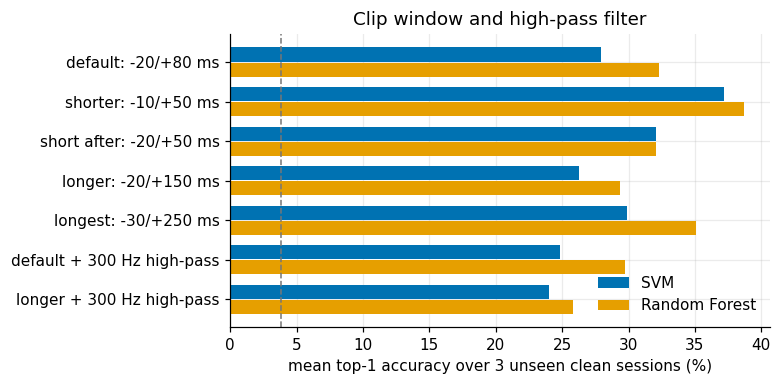

In [14]:
variants = [("default: -20/+80 ms", 0.02, 0.08, 0), ("shorter: -10/+50 ms", 0.01, 0.05, 0),
            ("short after: -20/+50 ms", 0.02, 0.05, 0), ("longer: -20/+150 ms", 0.02, 0.15, 0),
            ("longest: -30/+250 ms", 0.03, 0.25, 0), ("default + 300 Hz high-pass", 0.02, 0.08, 300),
            ("longer + 300 Hz high-pass", 0.02, 0.15, 300)]
abl = []
for label, pre, post, hp in variants:
    df = build(CLEAN, pre, post, hp)
    s_acc, r_acc = [], []
    for held in CLEAN:
        r = run([s for s in CLEAN if s != held], held, df=df)
        s_acc.append(r["SVM"]["top1"]); r_acc.append(r["RF"]["top1"])
    abl.append(dict(variant=label, SVM_top1=np.mean(s_acc), RF_top1=np.mean(r_acc)))
abl = pd.DataFrame(abl)
display(abl.round(1))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
y = np.arange(len(abl))[::-1]
ax.barh(y + 0.19, abl.SVM_top1, 0.36, color=C_CLEAN, label="SVM")
ax.barh(y - 0.19, abl.RF_top1, 0.36, color=C_UNDER, label="Random Forest")
ax.set_yticks(y); ax.set_yticklabels(abl.variant)
ax.axvline(CHANCE1, color=C_GREY, ls="--", lw=1)
ax.set_xlabel("mean top-1 accuracy over 3 unseen clean sessions (%)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Clip window and high-pass filter")
fig.tight_layout(); fig.savefig(FIG / "ablations.png"); plt.show()

**Reading the result.** A shorter clip, from 10 ms before to 50 ms after the key-down, is the best variant: 37% (SVM) and 39% (Random Forest) mean top-1, against 28% and 32% for the default window, a gain of about 9 and 6 points. Longer windows do not help. The 300 Hz high-pass filter does not help either (25% against 28%): the low frequencies carry information the model can use, so removing them throws away signal. Because the variants were compared on the same three sessions, the gain is probably somewhat optimistic and should be confirmed on a held-out session before adopting the shorter window.

## 11. Real-time style test (replay of the live demo)

The live demo (`demo/live_guess.py`) asks me to press a random key three times, finds the clicks **from the audio alone** (no key log), and shows the model's top 3 guesses with a confidence. The three presses are combined by multiplying their probabilities, since they are the same key.

Here the same code is run on the recorded bursts of a clean session the model never heard (trained on 06 and 07, replayed on 11), one burst per letter. This tests two things at once: the click finder and the three-press combination.

In [15]:
spec = importlib.util.spec_from_file_location("live_guess", ROOT / "demo" / "live_guess.py")
lg = importlib.util.module_from_spec(spec); spec.loader.exec_module(lg)

tr = ALL[ALL.session.isin(TRAIN_BASE)]
model = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma="scale", C=10, probability=True, random_state=SEED)).fit(tr[FEAT].values, tr.key.values)
payload = dict(model=model, classes=list(model.classes_), pre=PRE, post=POST, highpass=0.0)

rows = []
for key in ef.KEYS:
    a, sr = sf.read(RAW / BASELINE_TEST / f"{key}_burst.wav", dtype="float32")
    a = a[:, 0] if a.ndim == 2 else a
    g = lg.guess(payload, a, sr)
    if not g["ok"]:
        rows.append(dict(target=key, detected=False)); continue
    t3 = g["top3"]
    rows.append(dict(target=key, detected=True, top1=t3[0][0], conf1=t3[0][1], top2=t3[1][0], top3=t3[2][0],
                     hit1=t3[0][0] == key, hit3=key in [k for k, _ in t3],
                     single_press_hits=sum(p == key for p in g["per_press_top1"])))
rep = pd.DataFrame(rows)
det = rep[rep.detected]
print(f"letters replayed: {len(rep)}   with 3 clear clicks found from audio alone: {len(det)}")
print(f"combined 3 presses: top-1 {det.hit1.mean() * 100:.0f}% ({int(det.hit1.sum())}/{len(det)})   "
      f"top-3 {det.hit3.mean() * 100:.0f}% ({int(det.hit3.sum())}/{len(det)})   (chance 4% / 12%)")
print(f"single presses    : top-1 {det.single_press_hits.sum() / (3 * len(det)) * 100:.0f}% of {3 * len(det)} individual clicks")
print(f"uncertainty with only {len(det)} letters: roughly +/- {ci95(det.hit1.mean(), len(det)):.0f} points on top-1")
display(det[["target", "top1", "conf1", "top2", "top3", "hit1", "hit3"]].round(2).head(10))

letters replayed: 26   with 3 clear clicks found from audio alone: 26
combined 3 presses: top-1 35% (9/26)   top-3 62% (16/26)   (chance 4% / 12%)
single presses    : top-1 28% of 78 individual clicks
uncertainty with only 26 letters: roughly +/- 18 points on top-1


,target,top1,conf1,top2,top3,hit1,hit3
0,A,A,0.55,Q,Y,True,True
1,B,B,0.35,M,A,True,True
2,C,C,0.21,X,H,True,True
3,D,X,0.67,F,S,False,False
4,E,U,0.27,X,J,False,False
5,F,V,0.31,C,X,False,False
6,G,G,0.35,H,Y,True,True
7,H,J,0.39,K,U,False,False
8,I,U,0.75,Y,Q,False,False
9,J,O,0.37,I,J,False,True


**Reading the result.** The click finder found three clear clicks in all 26 bursts without using any key log. Combining the three presses gives 35% top-1 and 62% top-3, better than single clicks (28%), which fits the idea that more evidence about the same key helps. With only 26 letters the uncertainty is about ±18 points, so this is a demonstration of the pipeline rather than a precise accuracy figure.

## 12. Limitations and honest conclusions

**Limitations**
- **One laptop, one typist, one room.** The results describe this keyboard and this typing style, not keyboards in general.
- **Small data.** A session has 5 presses per key, so each test set has about 130 presses and a top-1 result carries about ±7 points of uncertainty. Several of the differences discussed above are inside that uncertainty.
- **Segmentation uses logged key times** in the main experiments. A real attacker would have to find the clicks from audio; the replay test shows a simple click finder works for isolated presses, but continuous typing with overlapping keys was not tested.
- **Isolated bursts, not real typing.** Each recording is five presses of one key, about one second apart, not a sentence typed at speed.
- **Sessions of the same defence are not identical.** For example the two cloth sessions differ in how loud the keys were, and the two noise sessions differ a little in their high-frequency content. This makes the adaptive test somewhat harder than it would be with a perfectly repeated setup.
- **Different recording times.** Background rumble changed between sessions (a low-frequency component only), which can move the clean baseline.
- **Variant selection on the same sessions** (ablations) is slightly optimistic.

**What I would do next:** more sessions per condition, a held-out final test session that is not touched while choosing anything, typing of real words, other typists and keyboards.

**Conclusions**

1. **The attack works, modestly.** On sessions it has never heard, the attacker identifies the exact key about 22% to 35% of the time and has the right key in its top 5 about 58% to 72% of the time, against 4% and 19% for guessing.
2. **Honest testing matters.** A random split would have reported 55%; the session-separated result is 28%.
3. **Defences, strongest first:** white noise (accuracy falls to chance for a clean-trained attacker and stays near chance for an adaptive one), then the cloth over the keys (a clear drop, partly recovered by an adaptive attacker), then the cloth under the stand (no reliable effect).
4. **Cheap improvements to the attack exist:** a shorter clip window (about +9 points, to be confirmed), more training sessions and combining several presses. A 300 Hz high-pass filter did not help.
5. **The sample is small.** Each test has about 130 presses and a ±7 point uncertainty, so only the large effects (noise, cloth over the keys, session-separation, window length) are solid.

## 13. How to re-run with more sessions

1. Record a new session with `python src/recording.py` (the key logger is part of it).
2. Add the session name to `CLEAN` (clean sessions) or to `DEFENDED` / `DEFENCES` in the configuration cell near the top of this notebook.
3. Run all cells again. Everything is recomputed from the raw audio; the figures are saved to `final_notebook/figures/`.

Keep one clean session **out** of every choice and look at it only once at the end: that is the honest final number.

*The numbers quoted in the written commentary belong to the run that produced this notebook. After adding sessions, re-read the commentary against the new tables.*